In [3]:
# 0. Programming Environment Setup

# basics
import os
import numpy as np
import pprint as pp

# pandas is used to read/process data
import pandas as pd

# machine learning dependencies
# scaling of data
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
# train/test split
from sklearn.model_selection import train_test_split
# model selection
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, validation_curve
# linear models (ordinary least squares, ridge and LASSO)
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso
# pipeline to streamline modeling pipelines
from sklearn.pipeline import Pipeline
# principal component analysis
from sklearn.decomposition import PCA
# polynomial feature mapping
from sklearn.preprocessing import PolynomialFeatures
# Dummy model as baseline
from sklearn.dummy import DummyClassifier, DummyRegressor
# Variance Threshold for feature selection
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
# metrics to measure model performance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, r2_score,
                             mean_absolute_error, mean_squared_error, max_error, mean_absolute_percentage_error)
# non-linear models
from xgboost import XGBRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor


# save/load models
import joblib

# For the permutation importance implementation
from joblib import Parallel
from joblib import delayed
from sklearn.metrics import check_scoring
from sklearn.utils import Bunch
from sklearn.utils import check_random_state
from sklearn.utils import check_array

# plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline

In [4]:
# 1. Data Preparation

# Fix random seed
RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)

# Import Data
df = pd.read_csv("Cleaned Data.csv")

# Remove rows containing missing values
df.dropna(inplace=True)

# Define features and target variable
TARGET = 'log_half_life'
FEATURES = [col for col in df.columns if col != TARGET and col != 'element']

# Split the data into training and testing sets
df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_SEED
)

# Define a function to get regression metrics
def get_regression_metrics(model, X, y_true):
    """
    Get a dicionary with regression metrics:

    model: sklearn model with predict method
    X: feature matrix
    y_true: ground truth labels
    """
    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)


    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'rmse': rmse,
        'r2': r2,
        'max_error': maximum_error,
    }

    return metrics_dict

# Define function for parity plots
def hist_density(y_true, y_pred, xlabel='y true', ylabel='y pred',
                 title=None, bins=50, ax=None, lims=None):
    """Parity plot drawn as a 2D histogram.

    y_true: true values
    y_pred: predicted values
    ax: optional Matplotlib subplot
    lims: optional shared axis limits
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    if lims is None:
        lims = [
            min(y_true.min(), y_pred.min()),
            max(y_true.max(), y_pred.max())
        ]

    mae = np.mean(np.abs(y_true - y_pred))

    # Create a figure only if no axis is provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(5.5, 4.5))
    else:
        fig = ax.figure

    # Plot 2D histogram
    h = ax.hist2d(
        y_true, y_pred,
        bins=bins,
        range=[lims, lims],
        cmin=1,
        cmap='viridis',
        norm=LogNorm()
    )

    # Add colorbar
    fig.colorbar(h[3], ax=ax, label='Number of Isotopes')

    # Add perfect prediction line
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')

    # Set axis labels and title
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(
        f"{title} (MAE = {mae:.2f})"
        if title else f"MAE = {mae:.2f}"
    )

    ax.legend(loc='upper left')
    ax.set_xlim(lims)
    ax.set_ylim(lims)

    # Display only if standalone
    if ax is not None and fig.axes[0] == ax and len(fig.axes) == 2:
        pass

    return ax


In [5]:
# 2. Build Baseline Models

# Define Dummy Regressors
dummy_regressors = {
    'Dummy (mean)': DummyRegressor(strategy='mean'),
    'Dummy (median)': DummyRegressor(strategy='median')
}

# Initialize result dictionaries
dummy_models_train_results = {}
dummy_models_test_results = {}

# Train and evaluate each model
for name, regressor in dummy_regressors.items():

    # Fit model on training data
    regressor.fit(df_train[FEATURES], df_train[TARGET])

    # Evaluate on training set
    dummy_models_train_results[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    dummy_models_test_results[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create DataFrames
df_dummy_train_results = pd.DataFrame.from_dict(
    dummy_models_train_results, orient='index'
)

df_dummy_test_results = pd.DataFrame.from_dict(
    dummy_models_test_results, orient='index'
)

# Combine training and testing results side-by-side
df_dummy_comparison = pd.concat(
    {'Train': df_dummy_train_results, 'Test': df_dummy_test_results},
    axis=1
)

df_dummy_comparison.index.name = 'Model'

# Display results
print("Comparison of Dummy Regressor Performance\n")
display(df_dummy_comparison.round(4))

Comparison of Dummy Regressor Performance



Train                                      Test           \
                  mae      mse    rmse     r2 max_error     mae      mse   
Model                                                                      
Dummy (mean)    2.451  10.5041  3.2410  0.000   10.5366  2.4206  10.6393   
Dummy (median)  2.449  10.5141  3.2425 -0.001   10.6368  2.4191  10.5959   

                                          
                  rmse      r2 max_error  
Model                                     
Dummy (mean)    3.2618 -0.0067    9.4607  
Dummy (median)  3.2551 -0.0026    9.4183

In [11]:
# 3. Build Linear Regression Models

# Define Linear Regression models
linear_regressors = {
    'Linear Regression': LinearRegression(),

    'Lasso Regression': Pipeline([
        ('scaling', StandardScaler()),
        ('lasso', Lasso(alpha=1.0, max_iter=10000))
    ]),

    'Gradient Descent': Pipeline([
        ('scaling', StandardScaler()),
        ('gd', SGDRegressor(
            loss='squared_error',
            penalty=None,
            learning_rate='invscaling',
            eta0=0.01,
            max_iter=1000,
            random_state=RANDOM_SEED
        ))
    ])
}

# Define pipeline for optimized Gradient Descent
pipe_gd_opt = Pipeline([
    ('scaling', StandardScaler()),
    ('gd_opt', SGDRegressor(
        loss='squared_error',
        penalty=None,
        random_state=RANDOM_SEED
    ))
])

# Define hyperparameter grid
param_grid_gd = {
    'gd_opt__learning_rate': ['constant', 'invscaling', 'adaptive'],
    'gd_opt__eta0': [0.0001, 0.001, 0.01],
    'gd_opt__max_iter': [1000, 3000],
    'gd_opt__tol': [1e-3, 1e-4]
}

# Initialize optimization results dictionary
linear_optimization_results = {}

# Optimize Gradient Descent using 5-fold cross-validation
grid_gd = GridSearchCV(
    pipe_gd_opt,
    param_grid=param_grid_gd,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    verbose=1
)

# Fit using training data only
grid_gd.fit(df_train[FEATURES], df_train[TARGET])

# Store optimization results
linear_optimization_results['Gradient Descent'] = grid_gd

# Add optimized model to regression dictionary
linear_regressors['Gradient Descent - Optimized'] = grid_gd.best_estimator_

# Display best hyperparameters
print("\nGradient Descent Best Parameters:")
print(grid_gd.best_params_)
print("Cross-Validation MAE:", -grid_gd.best_score_)

# Initialize result dictionaries
linear_regressor_results_train = {}
linear_regressor_results_test = {}

# Train and evaluate each model
for name, regressor in linear_regressors.items():

    # Fit models that have not already been optimized
    if not name.endswith(' - Optimized'):
        regressor.fit(df_train[FEATURES], df_train[TARGET])

    # Evaluate on training set
    linear_regressor_results_train[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    linear_regressor_results_test[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create comparison DataFrames
df_linear_train_results = pd.DataFrame.from_dict(
    linear_regressor_results_train, orient='index'
)

df_linear_test_results = pd.DataFrame.from_dict(
    linear_regressor_results_test, orient='index'
)

# Combine training and testing results side-by-side
df_linear_comparison = pd.concat(
    {'Train': df_linear_train_results, 'Test': df_linear_test_results},
    axis=1
)

df_linear_comparison.index.name = 'Model'

# Display results
print("\nComparison of Linear Regression Model Performance\n")
display(df_linear_comparison.round(4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Gradient Descent Best Parameters:
{'gd_opt__eta0': 0.01, 'gd_opt__learning_rate': 'adaptive', 'gd_opt__max_iter': 1000, 'gd_opt__tol': 0.0001}
Cross-Validation MAE: 2.257756117453707

Comparison of Linear Regression Model Performance



Train                                     \
                                 mae      mse    rmse      r2 max_error   
Model                                                                     
Linear Regression             2.2498   9.3753  3.0619  0.1075   10.3937   
Lasso Regression              2.4510  10.5041  3.2410  0.0000   10.5366   
Gradient Descent              2.2578   9.3960  3.0653  0.1055   10.4124   
Gradient Descent - Optimized  2.2500   9.3754  3.0619  0.1075   10.4713   

                                Test                                     
                                 mae      mse    rmse      r2 max_error  
Model                                                                    
Linear Regression             2.3075  10.1358  3.1837  0.0409    9.8209  
Lasso Regression              2.4206  10.6393  3.2618 -0.0067    9.4607  
Gradient Descent              2.3106  10.1093  3.1795  0.0434    9.8762  
Gradient Descent - Optimized  2.3069  10.1296  3.1827  0.0415    9.8254

In [ ]:
# 4. Build Ridge Regression Models

# Define Ridge Regression models
ridge_regressors = {
    'Ridge': Ridge(alpha=1.0),
    'Ridge (Scaled)': Pipeline([
        ('scaling', StandardScaler()),
        ('ridge', Ridge(alpha=1.0))
    ]),
    'Kernel (RBF)': Pipeline([
        ('scaling', StandardScaler()),
        ('krr_rbf', KernelRidge(alpha=1.0, kernel='rbf'))
    ]),
    'Kernel (Polynomial)': Pipeline([
        ('scaling', StandardScaler()),
        ('krr_poly', KernelRidge(alpha=1.0, kernel='polynomial'))
    ])
}

# Define pipeline for optimized Kernel Ridge Regression
pipe_krr_opt = Pipeline([
    ('scaling', StandardScaler()),
    ('krr_opt', KernelRidge())
])

# Define hyperparameter grids for each kernel
param_grids_krr = {
    'Kernel (RBF)': {
        'scaling': [StandardScaler(), MinMaxScaler(), RobustScaler()],
        'krr_opt__kernel': ['rbf'],
        'krr_opt__alpha': [0.01, 0.1, 1, 10],
        'krr_opt__gamma': [0.001, 0.01, 0.1, 1]
    },

    'Kernel (Polynomial)': {
        'scaling': [StandardScaler(), MinMaxScaler(), RobustScaler()],
        'krr_opt__kernel': ['poly'],
        'krr_opt__alpha': [0.01, 0.1, 1, 10],
        'krr_opt__gamma': [0.001, 0.01, 0.1, 1],
        'krr_opt__degree': [2, 3, 4],
        'krr_opt__coef0': [0, 1]
    }
}

# Initialize optimization results dictionary
krr_optimization_results = {}

# Optimize each kernel separately using 5-fold cross-validation
for name, param_grid in param_grids_krr.items():

    # Initialize GridSearchCV
    grid_krr = GridSearchCV(
        pipe_krr_opt,
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    # Fit using training data only
    grid_krr.fit(df_train[FEATURES], df_train[TARGET])

    # Store optimization results
    krr_optimization_results[name] = grid_krr

    # Add optimized model to regression dictionary
    ridge_regressors[name + ' - Optimized'] = grid_krr.best_estimator_

    # Display best hyperparameters
    print(f"\n{name} Best Parameters:")
    print(grid_krr.best_params_)
    print("Cross-Validation MAE:", -grid_krr.best_score_)

# Initialize result dictionaries
ridge_regressor_results_train = {}
ridge_regressor_results_test = {}

# Train and evaluate each model
for name, regressor in ridge_regressors.items():

    # Fit models that have not already been optimized
    if not name.endswith(' - Optimized'):
        regressor.fit(df_train[FEATURES], df_train[TARGET])

    # Evaluate on training set
    ridge_regressor_results_train[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    ridge_regressor_results_test[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create comparison DataFrames
df_ridge_train_results = pd.DataFrame.from_dict(
    ridge_regressor_results_train, orient='index'
)

df_ridge_test_results = pd.DataFrame.from_dict(
    ridge_regressor_results_test, orient='index'
)

# Combine training and testing results side-by-side
df_ridge_comparison = pd.concat(
    {'Train': df_ridge_train_results, 'Test': df_ridge_test_results},
    axis=1
)

df_ridge_comparison.index.name = 'Model'

# Display results
print("\nComparison of Ridge Regression Model Performance\n")
display(df_ridge_comparison.round(4))


Kernel (RBF) Best Parameters:
{'krr_opt__alpha': 0.1, 'krr_opt__gamma': 1, 'krr_opt__kernel': 'rbf', 'scaling': StandardScaler()}
Cross-Validation MAE: 0.9958784499935767

Kernel (Polynomial) Best Parameters:
{'krr_opt__alpha': 1, 'krr_opt__coef0': 1, 'krr_opt__degree': 4, 'krr_opt__gamma': 0.1, 'krr_opt__kernel': 'poly', 'scaling': RobustScaler()}
Cross-Validation MAE: 1.5994348429832648

Comparison of Ridge Regression Model Performance



Train                                    \
                                    mae     mse    rmse      r2 max_error   
Model                                                                       
Ridge                            2.2518  9.4034  3.0665  0.1048   10.2670   
Ridge (Scaled)                   2.2499  9.3755  3.0619  0.1074   10.3489   
Kernel (RBF)                     1.1872  3.2490  1.8025  0.6907    8.1615   
Kernel (Polynomial)              1.4178  4.3677  2.0899  0.5842    9.6273   
Kernel (RBF) - Optimized         0.6385  0.9775  0.9887  0.9069    7.2747   
Kernel (Polynomial) - Optimized  1.3671  4.1883  2.0465  0.6013    9.1781   

                                   Test                                     
                                    mae      mse    rmse      r2 max_error  
Model                                                                       
Ridge                            2.3126  10.2031  3.1942  0.0345    9.7644  
Ridge (Scaled)                   2.3083  10.1395  3.1843  0.0406    9.8054  
Kernel (RBF)                     1.2125   3.4559  1.8590  0.6730    7.7499  
Kernel (Polynomial)              1.4236   4.6396  2.1540  0.5610    9.2796  
Kernel (RBF) - Optimized         0.8184   1.6188  1.2723  0.8468    6.1555  
Kernel (Polynomial) - Optimized  1.4096   4.5693  2.1376  0.5676    8.7080

In [ ]:
# 5. Build Tree-Based Regression Models

# Define tree-based regression models
tree_regressors = {
    'Decision Tree': DecisionTreeRegressor(
        random_state=RANDOM_SEED
    ),
    'Random Forest': RandomForestRegressor(
        random_state=RANDOM_SEED,
        n_jobs=1
    ),
    'XGBoost': XGBRegressor(
        objective='reg:squarederror',
        random_state=RANDOM_SEED,
        tree_method='hist',
        n_jobs=1
    )
}

# Define pipelines for optimized tree-based models
pipe_rf_opt = Pipeline([
    ('rf_opt', RandomForestRegressor(
        random_state=RANDOM_SEED,
        n_jobs=1
    ))
])

pipe_xgb_opt = Pipeline([
    ('xgb_opt', XGBRegressor(
        objective='reg:squarederror',
        random_state=RANDOM_SEED,
        tree_method='hist',
        n_jobs=1
    ))
])

# Define hyperparameter grids for each model
param_grids_tree = {
    'Random Forest': {
        'rf_opt__n_estimators': [100, 300, 500],
        'rf_opt__max_depth': [None, 10, 20],
        'rf_opt__min_samples_split': [2, 5],
        'rf_opt__min_samples_leaf': [1, 2],
        'rf_opt__max_features': [1.0, 'sqrt']
    },

    'XGBoost': {
        'xgb_opt__n_estimators': [100, 300, 500],
        'xgb_opt__max_depth': [3, 5],
        'xgb_opt__learning_rate': [0.01, 0.05, 0.1],
        'xgb_opt__subsample': [0.8, 1.0]
    }
}

# Match each model to its optimization pipeline
pipes_tree_opt = {
    'Random Forest': pipe_rf_opt,
    'XGBoost': pipe_xgb_opt
}

# Initialize optimization results dictionary
tree_optimization_results = {}

# Optimize each model separately using 5-fold cross-validation
for name, param_grid in param_grids_tree.items():

    # Initialize GridSearchCV
    grid_tree = GridSearchCV(
        pipes_tree_opt[name],
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=2,
        verbose=1
    )

    # Fit using training data only
    grid_tree.fit(df_train[FEATURES], df_train[TARGET])

    # Store optimization results
    tree_optimization_results[name] = grid_tree

    # Add optimized model to regression dictionary
    tree_regressors[name + ' - Optimized'] = grid_tree.best_estimator_

    # Display best hyperparameters
    print(f"\n{name} Best Parameters:")
    print(grid_tree.best_params_)
    print("Cross-Validation MAE:", -grid_tree.best_score_)

# Initialize result dictionaries
tree_regressor_results_train = {}
tree_regressor_results_test = {}

# Train and evaluate each model
for name, regressor in tree_regressors.items():

    # Fit models that have not already been optimized
    if not name.endswith(' - Optimized'):
        regressor.fit(df_train[FEATURES], df_train[TARGET])

    # Evaluate on training set
    tree_regressor_results_train[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    tree_regressor_results_test[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create comparison DataFrames
df_tree_train_results = pd.DataFrame.from_dict(
    tree_regressor_results_train, orient='index'
)

df_tree_test_results = pd.DataFrame.from_dict(
    tree_regressor_results_test, orient='index'
)

# Combine training and testing results side-by-side
df_tree_comparison = pd.concat(
    {'Train': df_tree_train_results, 'Test': df_tree_test_results},
    axis=1
)

df_tree_comparison.index.name = 'Model'

# Display results
print("\nComparison of Tree-Based Regression Model Performance\n")
display(df_tree_comparison.round(4))

Fitting 5 folds for each of 72 candidates, totalling 360 fits

Random Forest Best Parameters:
{'rf_opt__max_depth': None, 'rf_opt__max_features': 'sqrt', 'rf_opt__min_samples_leaf': 1, 'rf_opt__min_samples_split': 2, 'rf_opt__n_estimators': 500}
Cross-Validation MAE: 0.9136415499055541
Fitting 5 folds for each of 36 candidates, totalling 180 fits

XGBoost Best Parameters:
{'xgb_opt__learning_rate': 0.05, 'xgb_opt__max_depth': 5, 'xgb_opt__n_estimators': 500, 'xgb_opt__subsample': 0.8}
Cross-Validation MAE: 0.839549383386843

Comparison of Tree-Based Regression Model Performance



Train                                      Test  \
                              mae     mse    rmse      r2 max_error     mae   
Model                                                                         
Decision Tree              0.0000  0.0000  0.0000  1.0000    0.0000  0.9763   
Random Forest              0.3325  0.2609  0.5108  0.9752    3.6748  0.9258   
XGBoost                    0.0930  0.0165  0.1285  0.9984    0.8130  0.8579   
Random Forest - Optimized  0.3208  0.2525  0.5025  0.9760    3.2379  0.8856   
XGBoost - Optimized        0.2128  0.0849  0.2913  0.9919    1.5753  0.8577   

                                                             
                              mse    rmse      r2 max_error  
Model                                                        
Decision Tree              2.5921  1.6100  0.7547    8.2048  
Random Forest              2.0113  1.4182  0.8097    6.9923  
XGBoost                    1.6922  1.3009  0.8399    6.9147  
Random Forest - Optimized  1.9521  1.3972  0.8153    7.2949  
XGBoost - Optimized        1.8287  1.3523  0.8270    7.3956

Comparison of All Regression Model Performance




Dummy Regression Parity Plots



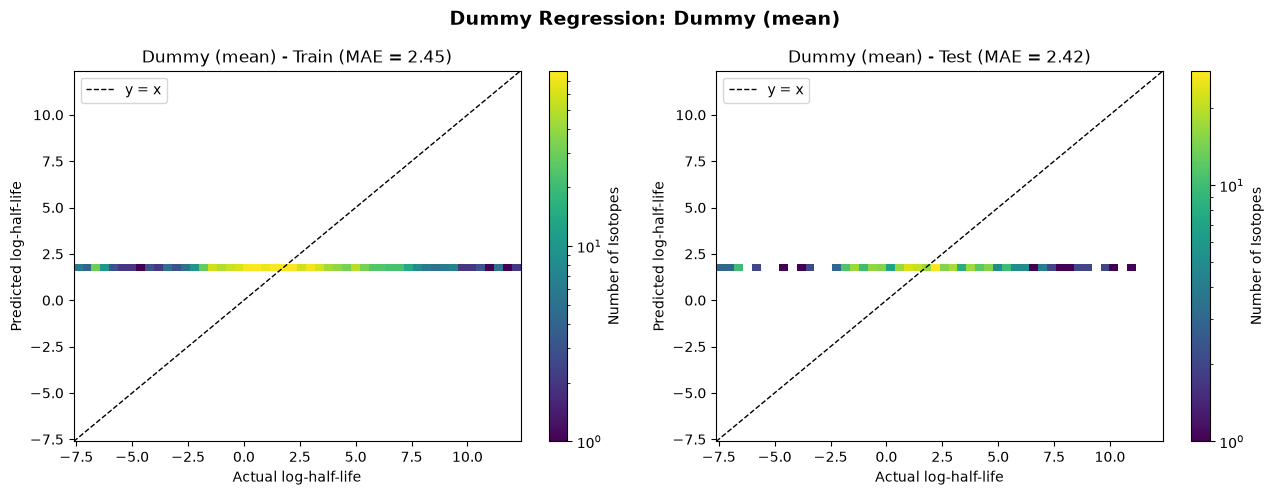

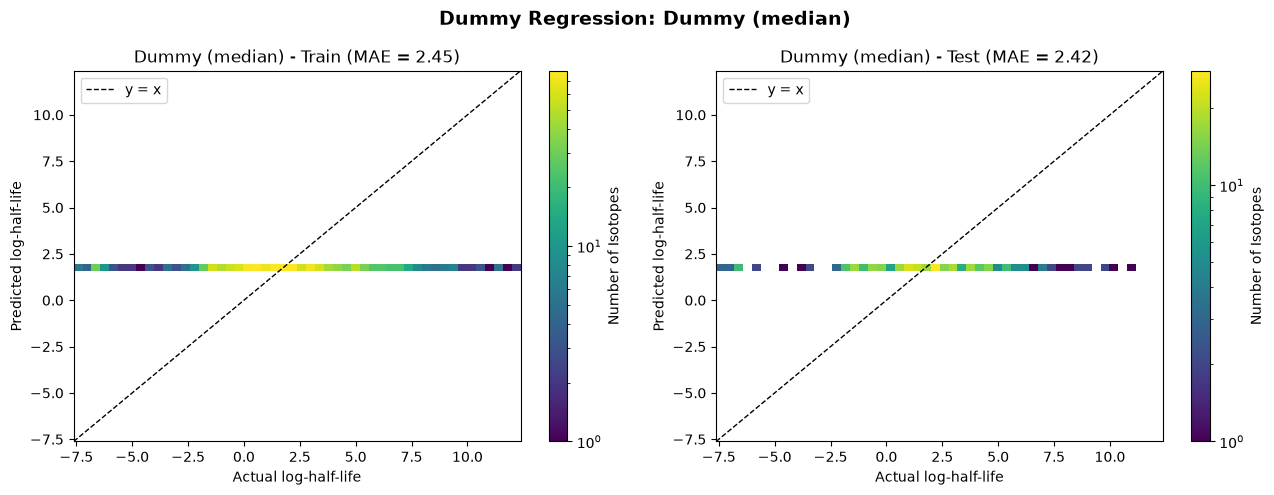


Linear Regression Parity Plots



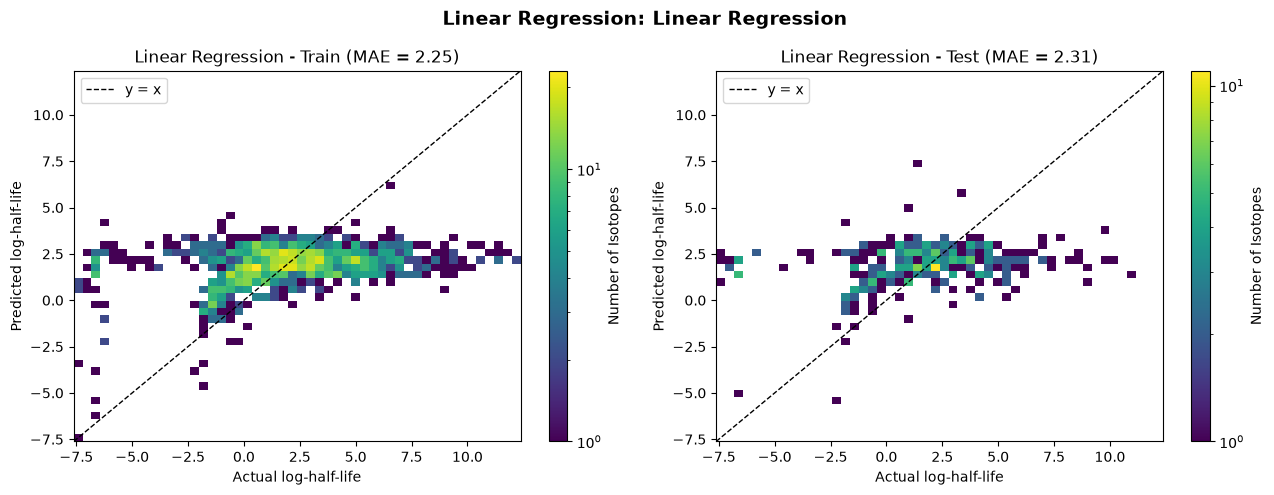

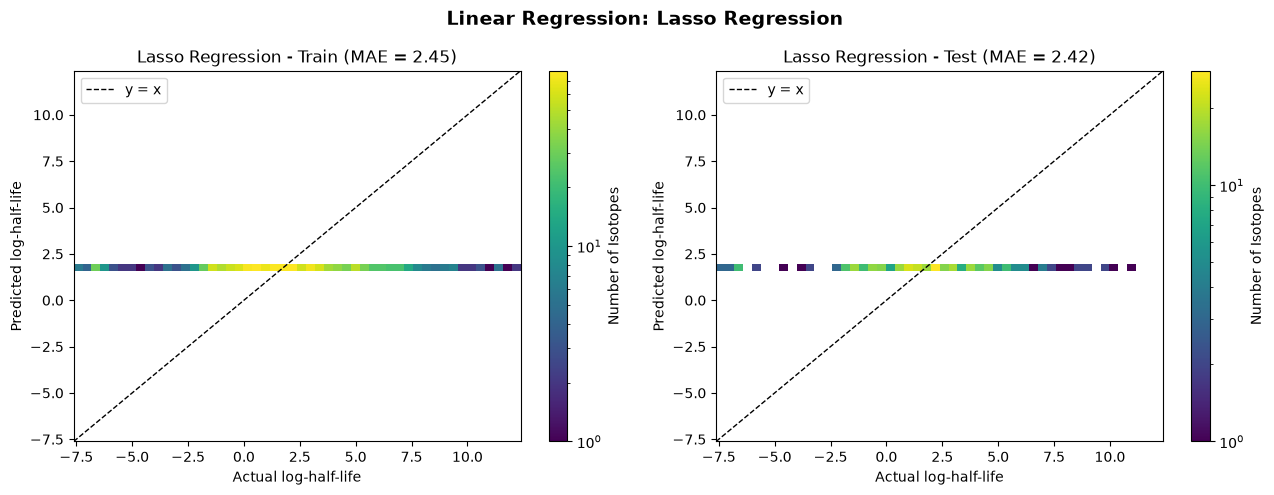

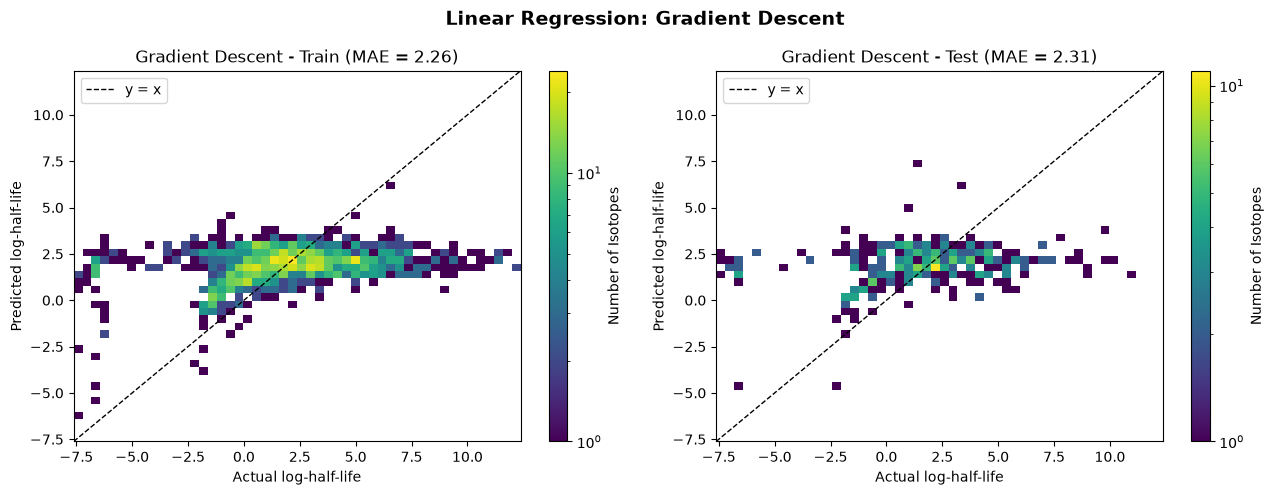

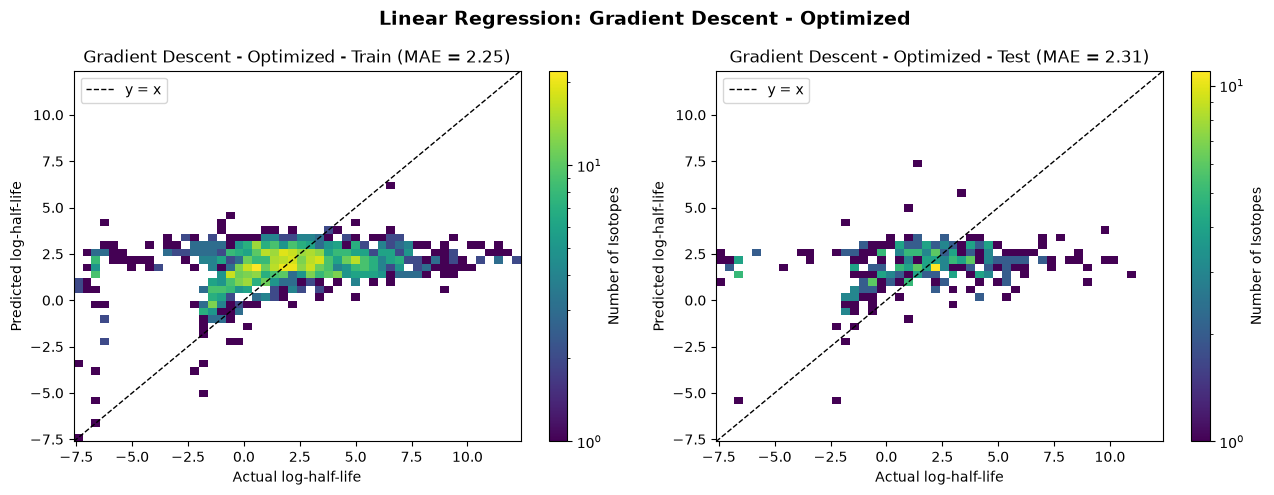


Ridge Regression Parity Plots



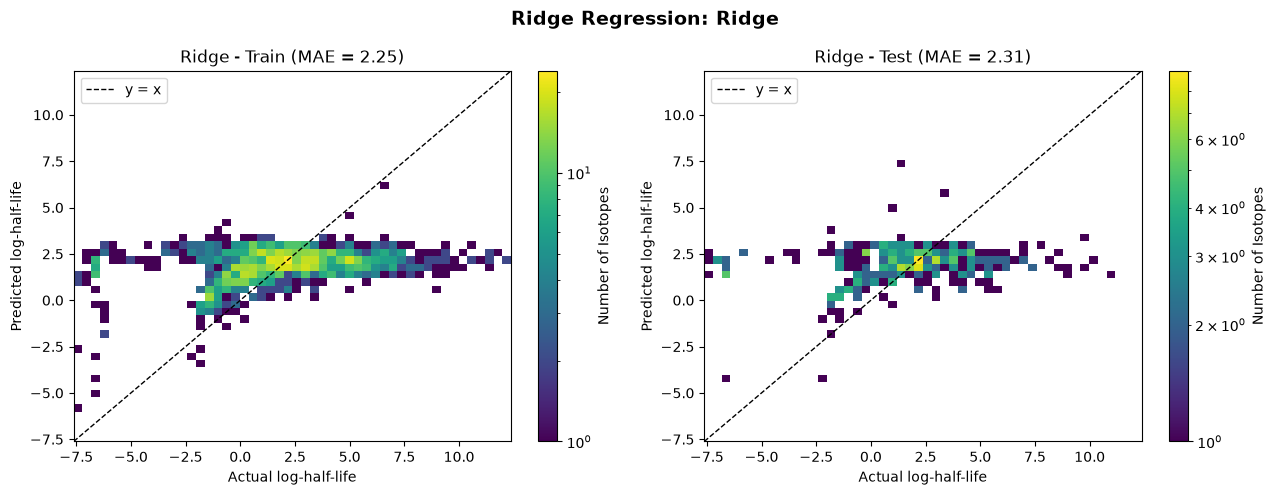

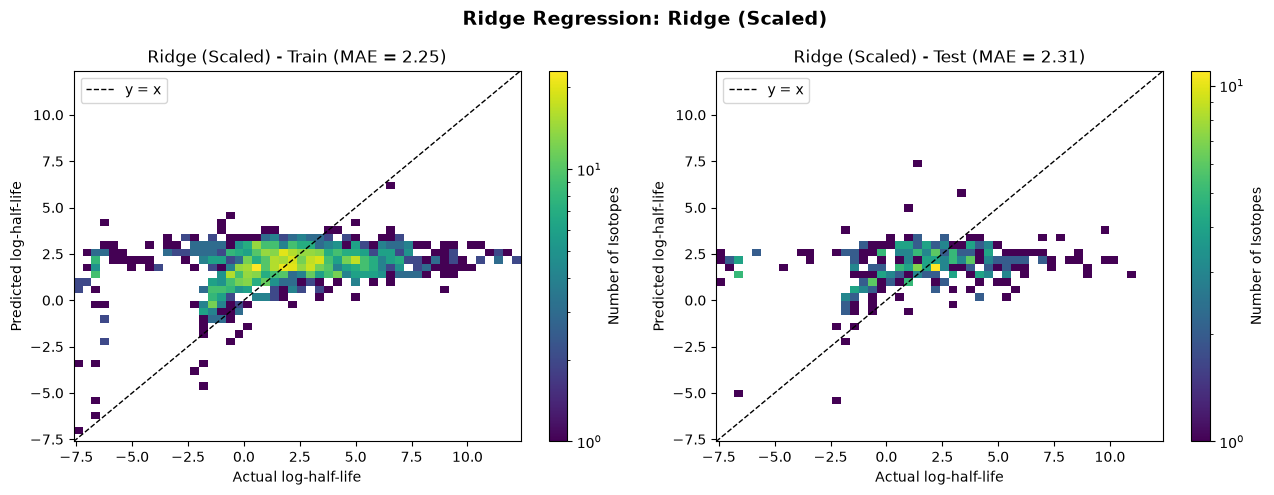

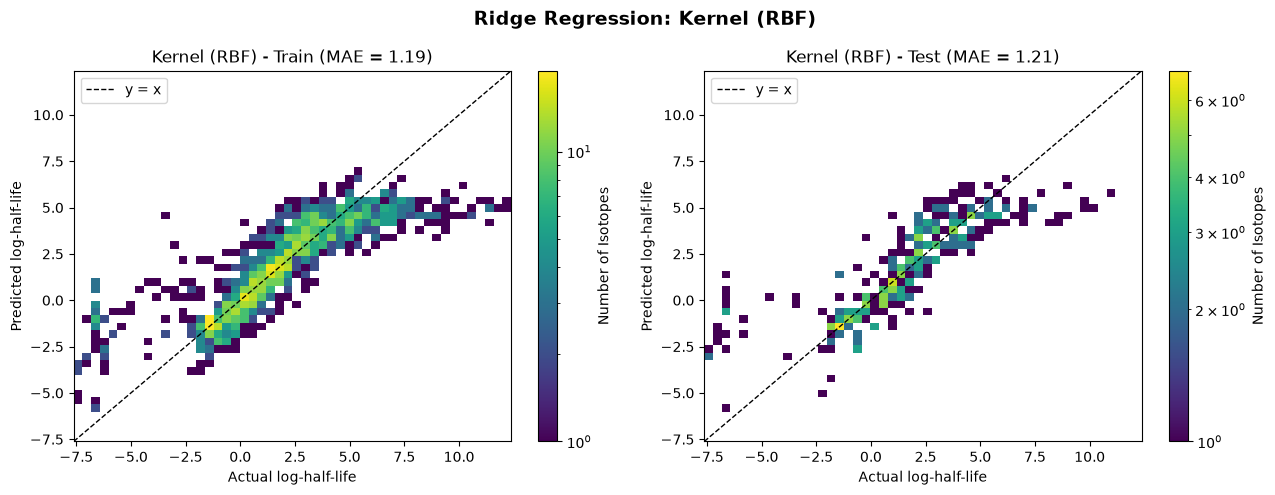

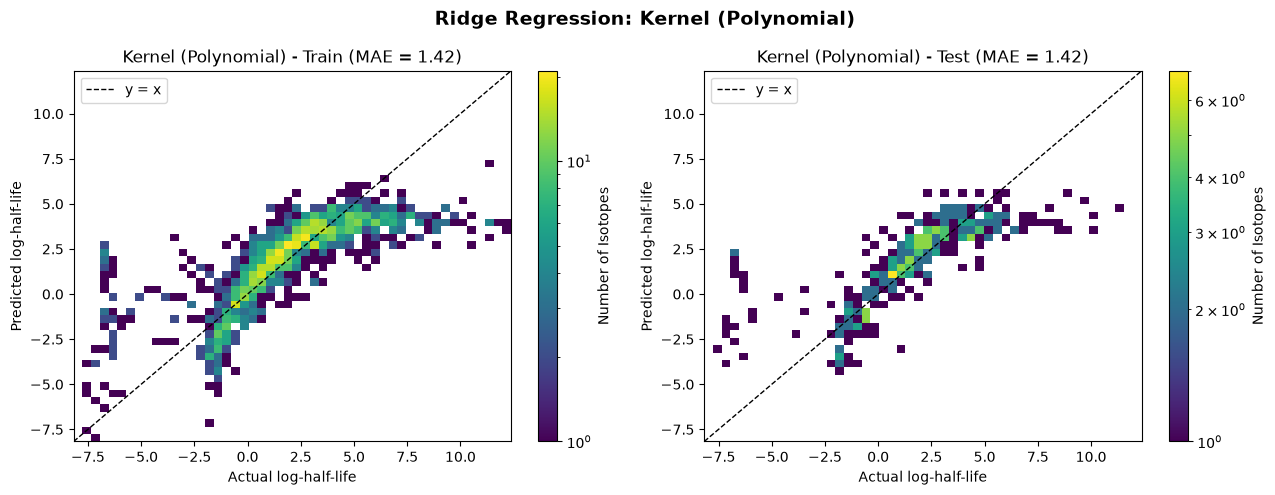

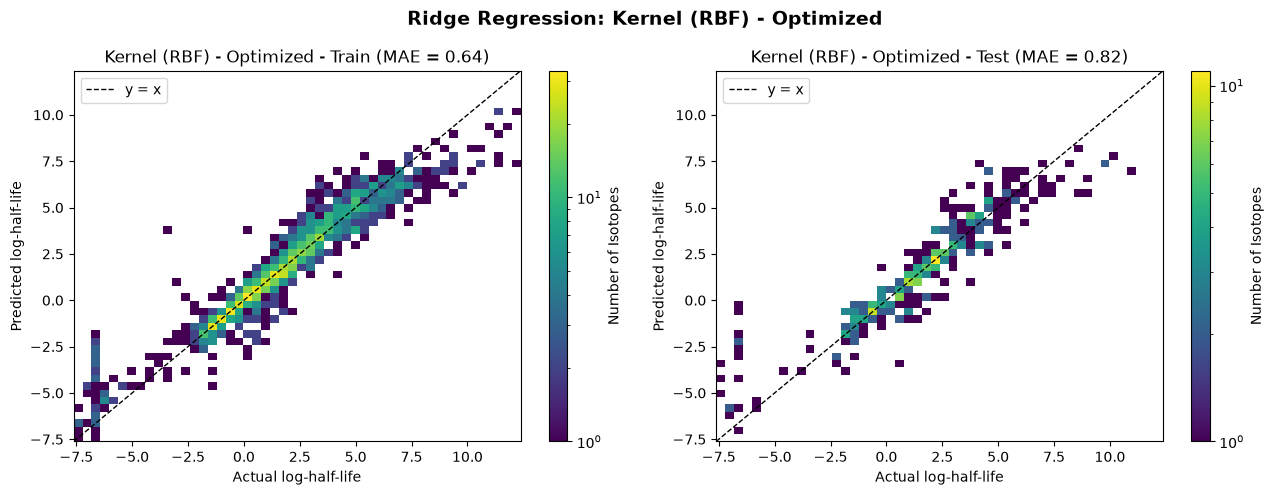

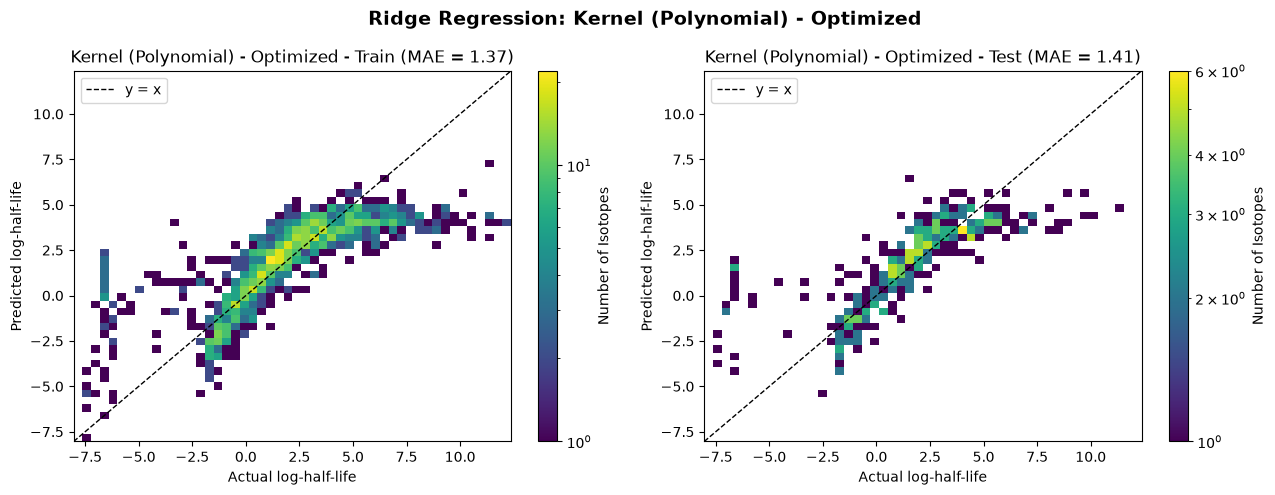


Tree-Based Regression Parity Plots



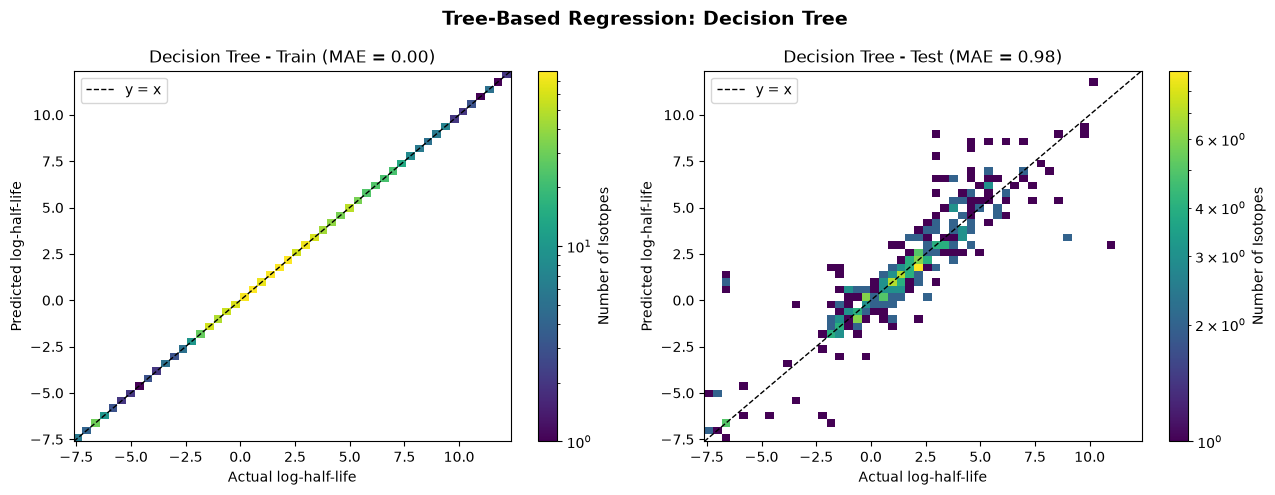

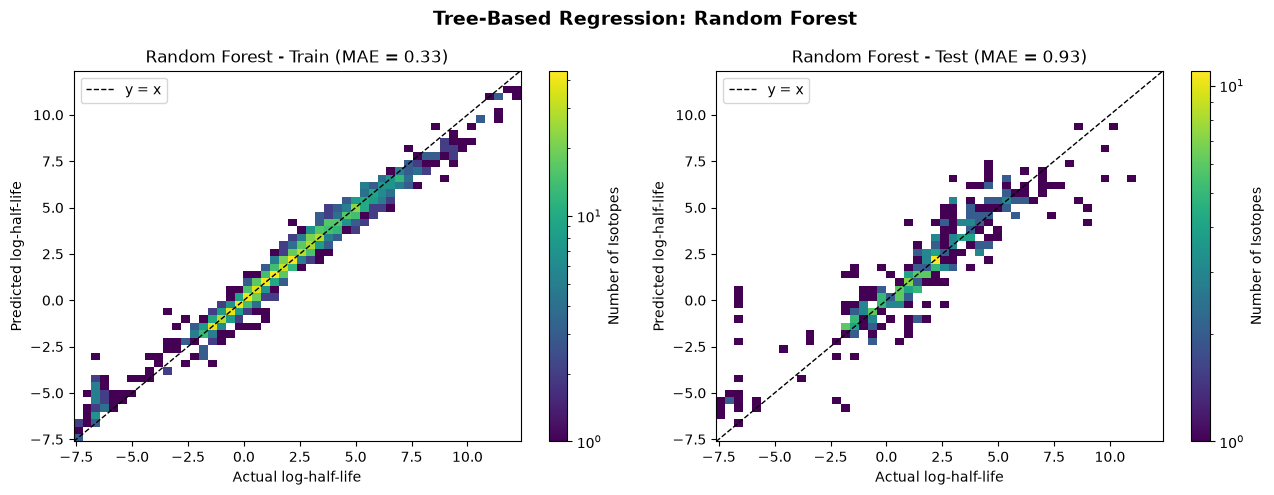

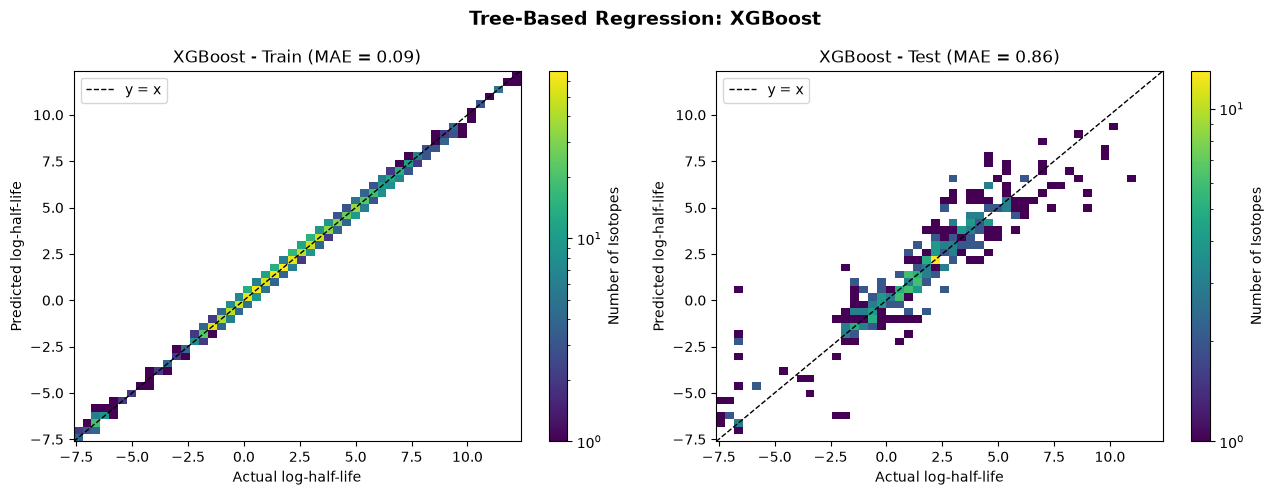

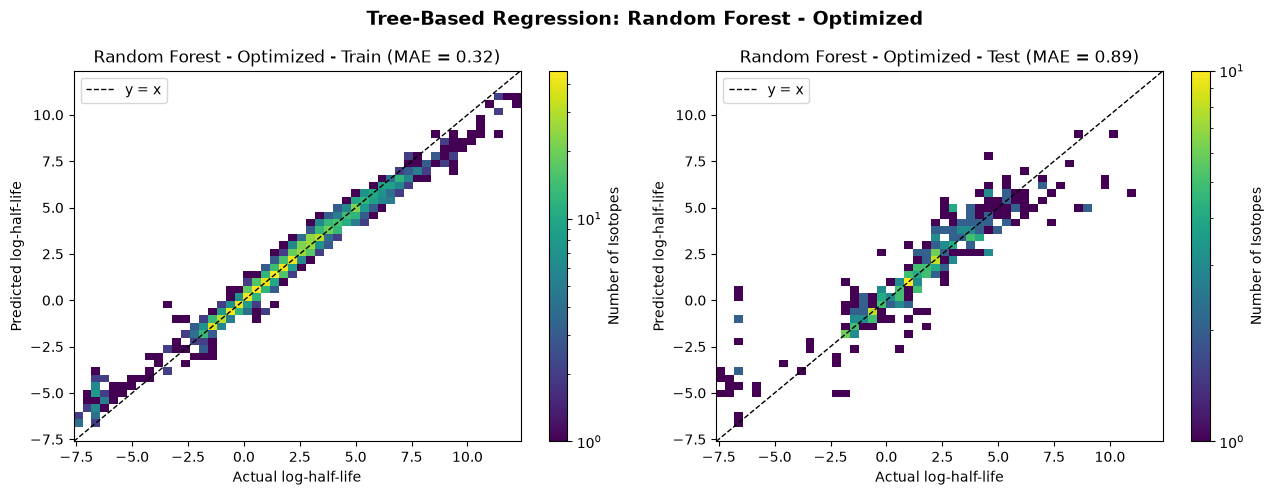

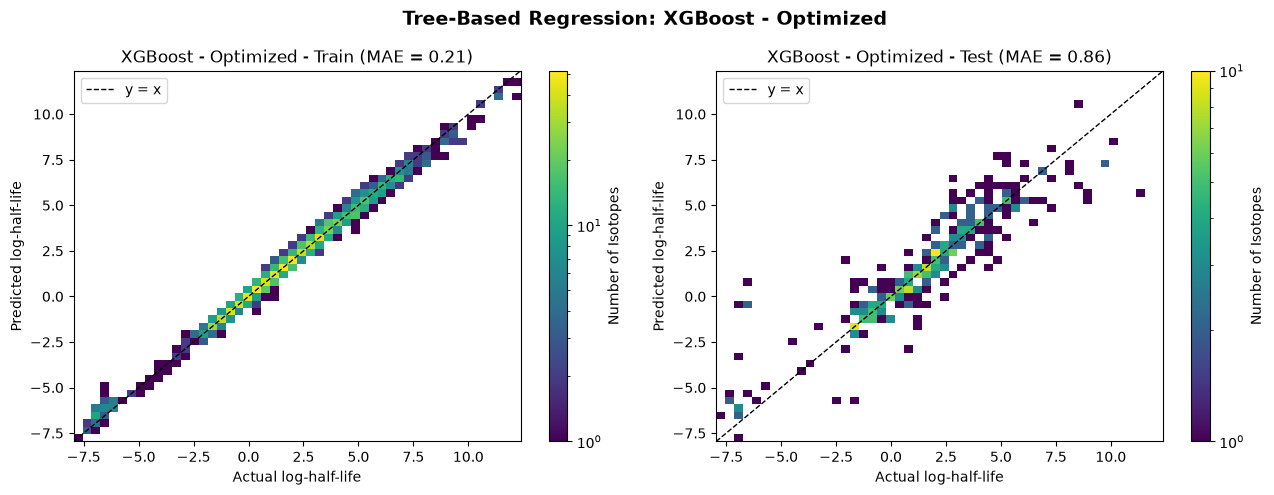

In [12]:
# 6. Model Comparison and Visualization

# Combine all regression model results
df_all_results = pd.concat(
    {
        'Dummy Regression': df_dummy_comparison,
        'Linear Regression': df_linear_comparison,
        'Ridge Regression': df_ridge_comparison,
        'Tree-Based Regression': df_tree_comparison
    },
    axis=0,
    names=['Model Category', 'Model']
)

# Convert index levels into regular columns
df_summary = df_all_results.reset_index()

# Create two-level column headers
df_summary.columns = pd.MultiIndex.from_tuples(
    [('', 'Model Category'), ('', 'Model')] +
    list(df_all_results.columns)
)

# Identify numerical metric columns
metric_cols = df_summary.columns[2:]

# Identify the first and last rows of each model category
categories = df_summary[('', 'Model Category')]

group_starts = categories.ne(categories.shift())
group_ends = categories.ne(categories.shift(-1))

# Add distinct borders around each model category
def style_model_groups(data):
    styles = pd.DataFrame(
        '', index=data.index, columns=data.columns
    )

    # Apply borders to each category section
    for i in range(len(data)):
        for j in range(len(data.columns)):
            borders = []

            if group_starts.iloc[i]:
                borders.append('border-top: 2px solid #666')

            if group_ends.iloc[i]:
                borders.append('border-bottom: 2px solid #666')

            if j == 0:
                borders.append('border-left: 2px solid #666')

            if j == len(data.columns) - 1:
                borders.append('border-right: 2px solid #666')

            styles.iloc[i, j] = '; '.join(borders)

    return styles

# Display formatted summary table
print("Comparison of All Regression Model Performance\n")

display(
    df_summary.style
    .format("{:.4f}", subset=metric_cols)
    .apply(style_model_groups, axis=None)
    .set_properties(**{
        'text-align': 'center',
        'vertical-align': 'middle'
    })
    .set_properties(
        subset=[('', 'Model')],
        **{'text-align': 'left'}
    )
    .set_table_styles([
        {
            'selector': 'th.col_heading',
            'props': [
                ('text-align', 'center'),
                ('vertical-align', 'middle'),
                ('font-weight', 'bold')
            ]
        },
        {
            'selector': 'th.col_heading.level0',
            'props': [
                ('text-align', 'center')
            ]
        },
        {
            'selector': 'th.col_heading.level1',
            'props': [
                ('text-align', 'center')
            ]
        }
    ])
)


# Combine fitted regression models
all_regressors = {
    'Dummy Regression': dummy_regressors,
    'Linear Regression': linear_regressors,
    'Ridge Regression': ridge_regressors,
    'Tree-Based Regression': tree_regressors
}

# Generate plots for each model category
for category, regressors in all_regressors.items():

    print(f"\n{category} Parity Plots\n")

    for name, model in regressors.items():

        # Predict training and testing values
        y_train_pred = model.predict(df_train[FEATURES])
        y_test_pred = model.predict(df_test[FEATURES])

        # Determine shared axis limits
        lims = [
            min(
                df_train[TARGET].min(),
                df_test[TARGET].min(),
                y_train_pred.min(),
                y_test_pred.min()
            ),
            max(
                df_train[TARGET].max(),
                df_test[TARGET].max(),
                y_train_pred.max(),
                y_test_pred.max()
            )
        ]

        # Create side-by-side subplots
        fig, axes = plt.subplots(
            1, 2, figsize=(13, 5)
        )

        # Training parity plot
        hist_density(
            df_train[TARGET],
            y_train_pred,
            xlabel='Actual log-half-life',
            ylabel='Predicted log-half-life',
            title=f'{name} - Train',
            ax=axes[0],
            lims=lims
        )

        # Testing parity plot
        hist_density(
            df_test[TARGET],
            y_test_pred,
            xlabel='Actual log-half-life',
            ylabel='Predicted log-half-life',
            title=f'{name} - Test',
            ax=axes[1],
            lims=lims
        )

        # Add overall figure title
        fig.suptitle(
            f'{category}: {name}',
            fontsize=14,
            fontweight='bold'
        )

        plt.tight_layout()
        plt.show()
